In [50]:
from dotenv import load_dotenv
load_dotenv()

True

In [51]:
from langchain_groq import ChatGroq
from langgraph.graph import StateGraph, START, END
from typing import Literal, Optional
from pydantic import BaseModel, Field
from langchain_core.prompts import ChatPromptTemplate

## Libs for Agents
from langchain_community.utilities import GoogleSerperAPIWrapper
from langchain.agents import create_agent
from langchain.tools import tool

In [52]:
class FlowState(BaseModel):
    question: str = Field(description="User Asked Question")
    # Make category Optional with a default of None so it can be populated later
    category: Optional[Literal['coding', 'google_search', 'weather']] = Field(
        default=None, 
        description="Category of the question"
    )
    answer: str = Field(default="")

In [53]:
class QuestionCategory(BaseModel):
   category: Literal['coding', 'google_search', 'weather'] = Field(
        description="Classify the user question into one of these categories."
    )

In [54]:
llm = ChatGroq(model="openai/gpt-oss-20b", temperature=0.0)
structured_llm = llm.with_structured_output(QuestionCategory)

In [55]:
search = GoogleSerperAPIWrapper()
tools = [search.run]
google_agent = create_agent(
    model=llm,
    tools=tools,
    system_prompt="You are a agent and can search for any question on google."
)


## Weather Agent
@tool
def get_weather(city:str) -> str:
    """It provide real time weather details for any city"""

    query = f"current weather in {city}"
    search_results = search.run(query)
    
    return f"Here are the live weather search results for {city}: {search_results}"
    

weather_agent = create_agent(
    model=llm,
    tools=[get_weather],
    system_prompt="You are a agent and can provide real time weather details."
)

In [56]:
def check_question_category(state:FlowState) -> FlowState:
    st_llm = llm.with_structured_output(QuestionCategory)
    res = st_llm.invoke(f"I want to know the category of my question, question is : {state.question}. If you are not sure then just give 'google_search' as a category")
    state.category = res.category
    return state

In [57]:
def route(state:FlowState) -> Literal['coding', 'google_search', 'weather']:
    return state.category

In [58]:
def coding_node(state:FlowState) -> FlowState:
    print("Coding NODE...")
    res = llm.invoke(f"You are a coding expert: {state.question}")
    state.answer = res.content
    return state


def weather_node(state:FlowState) -> FlowState:
    res = weather_agent.invoke({"messages":[
        {"role":"user", "content":state.question}
    ]})
    state.answer = res["messages"][-1].content
    return state


def google_search_node(state:FlowState) -> FlowState:
    res = google_agent.invoke({"messages":[
        {"role":"user", "content":state.question}
    ]})
    state.answer = res["messages"][-1].content
    return state

In [59]:
graph = StateGraph(FlowState)

graph.add_node("check_question_category", check_question_category)
graph.add_node("coding", coding_node)
graph.add_node("weather", weather_node)
graph.add_node("google_search", google_search_node)

graph.add_edge(START, "check_question_category")
graph.add_conditional_edges("check_question_category", route)
graph.add_edge("coding", END)
graph.add_edge("weather", END)
graph.add_edge("google_search", END)

graph = graph.compile()

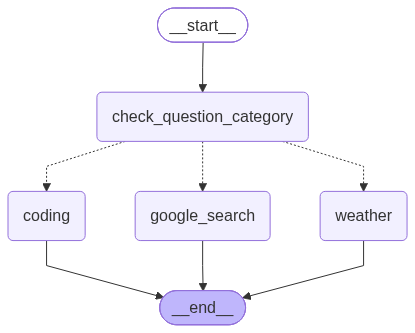

In [60]:
from IPython.display import Image
Image(graph.get_graph().draw_mermaid_png())

In [63]:
response = graph.invoke({"question":"What is the temperature in Moradabad right now  ?"})

In [64]:
response

{'question': 'What is the temperature in Moradabad right now  ?',
 'category': 'weather',
 'answer': '**Moradabad – Current Temperature (as of the latest update)**  \n- **79\u202f°F** (≈\u202f26\u202f°C)  \n- Weather: Clear\n\n*(Data retrieved from the live weather feed.)*'}